In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em17"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230226_17'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230226_17/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DIVIDE_BY_BTAG = False
EXPORT_VARIABLE = False

# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566538,
    "ee16post":287977115,
    "ee17":460041185,
    "ee18":1326465848,
    "mm16pre":458655574,
    "mm16post":327037313,
    "mm17":739073838,
    "mm18":944833120,    
    "em16pre":652566538,
    "em16post":287977115,
    "em17":460041185,
    "em18":1326465848     
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*M*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

em17 41480


  0%|          | 0/194 [00:00<?, ?it/s]

DY0


  1%|          | 1/194 [00:00<01:18,  2.47it/s]

DY1


...

 99%|█████████▉| 192/194 [01:22<00:01,  1.89it/s]

Zp-4100_CH-595


 99%|█████████▉| 193/194 [01:23<00:00,  1.95it/s]

Zp-4100_CH-845


100%|██████████| 194/194 [01:23<00:00,  2.31it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
7798049
DY1
8244133
DY10
8510387
high DY1000To15000
DY11
8944052
DY12
9114037
DY13
9770787
DY14
8648737
DY15
1585487
high DY1500To20000
DY2
8666850
high DY2000To30000
DY3
6670651
DY4
9460659
DY5
9052002
high DY500To7000
DY6
7854873
DY7
8014614
high DY700To8000
DY8
10001888
high DY800To10000
DY9
9207802


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTSemi_concat:
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 112771456
TTSemi: 343257666
TTZ: 6911466
DY: 131545008
top: 5648712
antitop: 5673700
ZZ: 40757252
WZ: 6826898
WW: 7071430
Data: 1199115020


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
#try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
#except (ValueError, IndexError):
#    beepno()
#    raise

In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


Warning, nan in top
Int64Index([137], dtype='int64')
Warning, nan in antitop
Int64Index([173, 1281, 1634, 401], dtype='int64')
Warning, nan in WZ
Int64Index([25185], dtype='int64')


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weight"] *= vs[1][s]
            dic_df_met_d[key]["weight"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
        dic_df[key]["btag0"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
#             if "top" in s1:
#                 continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
    return dic_df, dic_df_met_u, dic_df_met_d

dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.006725273399735692
DY1500To20000
DY1500To2000 : 0.0008913829700309587
DY2000To30000
DY2000To3000 : 0.00019855513765608545
DY500To7000
DY500To700 : 0.0660359101064856
DY700To8000
DY700To800 : 0.014978640672124085
DY800To10000
DY800To1000 : 0.012300589428593817
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009742269333333333
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009742269333333333
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009742269333333333
Zp-2100_CH-345
Zp-2100_CH-345 : 0.003312869333333333
Zp-2100_CH-595
Zp-2100_CH-595 : 0.003312869333333333
Zp-2100_CH-845
Zp-2100_CH-845 : 0.003312869333333333
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0012156405333333333
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0012156405333333333
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0012156405333333333
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0004889109333333333
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0004889109333333333
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0004889109333333333
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0004889109333333333
Zp-2900_C

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d[key]=dic_df_met_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u
nested_dic_df["met_d"]=dic_df_met_d

DY1000To1500 : 1025 ( 3.64251268026419 )
DY1500To2000 : 1418 ( 0.6774007899221033 )
DY2000To3000 : 1697 ( 0.16977663004217902 )
DY500To700 : 407 ( 11.156466565094888 )
DY700To800 : 509 ( 4.086255330359563 )
DY800To1000 : 734 ( 4.394334043143317 )
Zp-1700_CH-345 : 22444 ( 207.16937537001772 )
Zp-1700_CH-595 : 27478 ( 253.8634491654779 )
Zp-1700_CH-845 : 29879 ( 276.68932274843485 )
Zp-2100_CH-345 : 26191 ( 82.5527246693301 )
Zp-2100_CH-595 : 30928 ( 97.44582227610238 )
Zp-2100_CH-845 : 33849 ( 106.69096924514872 )
Zp-2500_CH-345 : 29098 ( 33.70569549551347 )
Zp-2500_CH-595 : 33189 ( 38.45189467245959 )
Zp-2500_CH-845 : 36239 ( 41.988729239978454 )
Zp-2900_CH-1095 : 39864 ( 18.643114276948886 )
Zp-2900_CH-1345 : 41552 ( 19.44151314183553 )
Zp-2900_CH-345 : 31321 ( 14.648305919827925 )
Zp-2900_CH-595 : 35169 ( 16.433998467881157 )
Zp-2900_CH-845 : 37889 ( 17.692941651909713 )
Zp-3300_CH-1095 : 40923 ( 7.903685555936569 )
Zp-3300_CH-1345 : 42652 ( 8.240109985834055 )
Zp-3300_CH-1595 : 4330

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [10, 100, 1000, "Puppi p_{T}^{miss} [GeV]"],    
    "PuppiMET_pre": [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [45, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_el_pre": [31, 20,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_mu_pre": [31, 20,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [29, 0, 660, "U [GeV]"],
#     "JZB_pre": [29, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#     "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF1_pre": [100, 0, 10, "SV dxy"],     
}
list_variables = [(key, dic_variable[key]) for key in dic_variable]


In [19]:
import math
sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/norm_"+query_str, is_dnn=False)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systUp_"+s+query_str, is_dnn=False)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systDown_"+s+query_str, is_dnn=False)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
        
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
    print(dic_sys)
    print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [20]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list1, variable, dic_variable[variable], region)
    
#     print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr)            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, is_dnn=False)   
    return None

{'puweightUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  1.18965682,
        6.25336827,  0.80955682,  5.4040513 ,  0.24904055,  1.41044093,
        1.28368662,  0.46596549,  1.23994461, -0.23967099,  0.16775917,
       -0.66267849,  0.15728494,  0.14318309, -0.04661875,  0.0820822 ,
        0.15081868,  0.09624527, -0.27184187,  0.16097125, -0.02048089,
        0.29560623, -0.02163453,  0.23332605]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.        , -7.33400901,
       -7.14563693, -8.0757575 , -3.67995057, -0.37666623, -0.48316575,
       -0.39498841, -0.69164495, -0.76647098, -0.14346288, -0.06924627,
        0.37372149, -0.22078137, -0.1396187 , -0.09456785, -0.06662197,
       -0.03846664, -0.09638035,  0.13141915, -0.15952969,  0.01850394,
       -0.08892368, -0.02861512, -0.01441506]), 'l1prefiringUp': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       4.18226493e+01, 3.69902443e+01, 2.30728652e+01, 1.47196612

       1.09712835e-01, 1.18675893e-01, 7.31706320e-02, 2.71776059e-01])}
{'puweightUp': array([ 3.09396076e+00,  1.37908922e+01,  2.93082294e+01,  1.06933178e+01,
       -3.80509105e+01, -2.41747008e+01,  4.94709911e-02,  6.11701525e+00,
        7.12430794e+00,  3.83187743e+00,  3.81689169e+00,  3.83992945e-01,
        9.78529153e-01,  9.82360076e-01,  9.41699798e-02, -5.94940734e-01,
        3.72848303e-01,  1.57854584e-02,  9.17796970e-02,  1.73014582e-01,
       -2.66531654e-01,  1.51762593e-01,  1.12842329e-01, -1.29442245e-01,
        4.65387746e-01, -6.93778407e-02, -1.49745885e-01,  3.17276189e-01]), 'puweightDown': array([ -2.84602565, -13.79587847, -31.66606693, -15.70799442,
        35.96391724,  24.63282489,  -2.18205389,  -8.47542526,
        -6.46441554,  -2.57853135,  -3.56913244,  -0.37508401,
        -0.81808629,  -0.88747792,  -0.28385794,   0.34993776,
        -0.36134491,  -0.04454639,  -0.09352254,  -0.17190654,
         0.10189791,  -0.15105753,  -0.06254866,   0.0

        0.09971552,  0.1686105 ,  0.30743177])}
{'puweightUp': array([-0.59536585, -2.33594042, -0.36861429, 11.07348038,  3.73477303,
        2.75938916,  4.56738637,  0.17597465, -1.31386883,  0.83275119,
       -1.77495997,  0.63250085,  1.83912157, -0.41295652, -0.09264186,
        0.36733162, -0.18724987,  0.10204068,  0.28132083, -0.03493038,
       -0.02264445, -0.1985597 , -0.04027912,  0.02638865, -0.17205625,
       -0.06818927,  0.03310128, -0.05232067, -0.02633267, -0.04317951,
       -0.15540788]), 'puweightDown': array([ 6.06424331e-02,  1.69672622e+00, -4.72745553e+00, -1.28122159e+01,
       -5.31983139e+00, -4.28137448e+00, -3.37682950e+00, -5.23049422e-01,
        1.02539545e+00, -6.11560744e-01,  1.42713241e+00, -3.03576215e-01,
       -1.48334505e+00, -9.34832101e-02, -3.37310261e-01, -4.63498916e-01,
        2.33302201e-01, -2.03590947e-01, -1.98479220e-01, -2.43974604e-02,
        6.78475461e-02,  1.45975993e-01,  1.02919411e-01, -2.82246687e-02,
        1.5149633

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([3.67750469e-03, 2.87887987e+00, 0.00000000e+00, 1.22621968e+02,
       1.39485296e+01, 7.61422853e+00, 2.08610183e+01, 3.09670786e-02,
       1.05143582e+00, 6.93474553e-01, 2.03670692e+00, 4.00057327e-01,
       3.38236816e+00, 0.00000000e+00, 0.00000000e+00, 1.34932517e-01,
       5.44299170e-02, 1.04122995e-02, 7.91414077e-02, 0.00000000e+00,
       4.60328951e-03, 2.13089906e-02, 1.05924052e-02, 6.96360906e-04,
       2.29511403e-02, 1.07612775e-02, 1.09569462e-03, 1.08449739e-03,
       4.52942223e-05, 2.35165797e-03, 2.27615968e-02]), 'puweightDown': array([3.54460500e-01, 5.45661763e+00, 2.24847123e+01, 1.64152876e+02,
       2.83006060e+01, 1.83301675e+01, 1.14029775e+01, 2.73580698e-01,
       1.72625130e+00, 3.74006543e-01, 3.15048288e+00, 9.21585182e-02,
       2.20031253e+00, 1.79272201e-01, 1.22360726e-01, 2.14831245e-01,
       3.50625135e-02, 4.14492738e-02, 3.93940006e-02, 1.81536758e

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([7.04822209e+01, 3.03286358e+01, 2.11810634e+01, 5.82533743e+00,
       2.10763695e-02, 4.12690448e-02, 8.96371669e-01, 9.46060670e-02,
       3.12994191e+00, 8.16877472e-01, 2.88781144e+00, 6.16340197e-01,
       0.00000000e+00, 1.14762391e-01, 3.34806628e-02, 0.00000000e+00,
       2.07244028e-01, 7.04170933e-04, 1.37308192e-03, 2.90821081e-04,
       2.85232975e-02, 2.55814639e-02, 2.38300534e-04, 6.18105290e-03,
       9.32566188e-03, 9.30344363e-04, 1.73832006e-02, 1.88188953e-03,
       3.84643565e-03, 2.70343551e-03, 2.77770002e-02]), 'puweightDown': array([1.66891856e+02, 9.39139398e+01, 2.45575333e+01, 1.32167264e+01,
       0.00000000e+00, 2.23225623e+00, 1.56475534e+00, 0.00000000e+00,
       4.47211319e+00, 7.39324539e-02, 9.76589846e-01, 7.93114332e-01,
       9.18864806e-02, 2.22679438e-01, 6.29553256e-03, 9.40674587e-03,
       9.13045298e-02, 3.42272111e-03, 8.56516852e-03, 2.93997074e

       5.47637102e-02, 8.92929049e-02, 4.16352679e-01])}
{'puweightUp': array([ 0.65882712, 10.25089852,  6.41836788,  2.21493589,  4.05264096,
       -0.0847878 , -1.34558426, -1.70768379, -1.06472838, -1.05051061,
       -0.64338287,  0.40305881,  0.56194154,  0.80713091, -0.63933103,
       -0.20701923,  0.19758811, -0.14517044, -0.09911228, -0.09600271,
        0.12980303,  0.03192432, -0.15582884,  0.05820464, -0.0330429 ,
        0.07962098, -0.06106032,  0.13550149,  0.02225723, -0.09532737,
       -0.06406586]), 'puweightDown': array([-5.87213654e-02, -1.25227434e+01, -9.06307033e+00, -5.82385566e+00,
       -5.48405811e+00,  3.97771927e-01,  8.72014015e-02,  8.76932241e-01,
        4.30962152e-01,  7.31194703e-01,  6.13337626e-01, -7.29215939e-02,
       -1.51462830e-01, -5.13153370e-01,  7.51519593e-01,  3.12338115e-01,
       -2.04511048e-01,  4.79162193e-02,  1.68127030e-01,  5.81167323e-02,
       -1.53490883e-01,  2.28228639e-02,  1.26683079e-01, -7.01445091e-02,
        

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([4.34053174e-01, 1.05080920e+02, 4.11954463e+01, 4.90594101e+00,
       1.64238987e+01, 1.58222506e-01, 7.60408443e-03, 7.69010154e-01,
       1.85728376e-01, 5.34645694e-01, 3.76183043e-01, 1.62456403e-01,
       3.15778299e-01, 6.51460307e-01, 5.64781699e-01, 9.75550984e-02,
       3.90410612e-02, 2.29596407e-03, 2.82666981e-02, 3.37755457e-03,
       1.68488277e-02, 1.54004551e-03, 1.60486025e-02, 3.38778033e-03,
       1.66193496e-03, 6.33950097e-03, 0.00000000e+00, 1.83606538e-02,
       4.95384370e-04, 1.06779907e-02, 2.70134061e-06]), 'puweightDown': array([3.44819875e-03, 1.56819103e+02, 8.21392437e+01, 3.39172947e+01,
       3.00748933e+01, 7.18897059e-03, 1.81059701e+00, 2.91618393e+00,
       1.13364652e+00, 1.10357254e+00, 4.13941519e-01, 5.31755886e-03,
       2.29409887e-02, 2.63326381e-01, 4.08744167e-01, 4.28569614e-02,
       4.18247688e-02, 2.10744561e-02, 9.82324412e-03, 9.21651968e

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([2.16085243e-01, 1.28191291e+01, 1.66637020e+01, 9.73712204e-01,
       6.74190261e+00, 1.36106719e+01, 7.60591787e-01, 5.22995889e+00,
       1.60244201e-01, 2.79244132e+00, 5.13342778e-01, 2.07073678e+00,
       3.80269955e-01, 2.25830926e+00, 0.00000000e+00, 4.69463440e-01,
       2.75059400e-01, 3.96092621e-04, 9.16602252e-01, 3.52496868e-02,
       3.44711196e-03, 2.26418632e-02, 5.85710865e-02, 0.00000000e+00,
       2.11727988e-01, 0.00000000e+00, 1.92084779e-02, 1.44644548e-02,
       7.81214664e-03, 0.00000000e+00, 1.88342206e-02, 4.51344529e-03,
       2.67238224e-02, 3.42704652e-03, 9.65562333e-03, 7.63920115e-03,
       0.00000000e+00, 4.44434046e-03, 0.00000000e+00, 2.79313696e-03,
       1.26900303e-05, 1.31551690e-02, 7.58490103e-04, 0.00000000e+00,
       1.53991916e-03]), 'puweightDown': array([1.81526796e+00, 1.37207589e+01, 4.77873742e+01, 6.80847679e+00,
       1.37654229e+01, 3.34111200e+01, 

        0.10032298,  0.12762409,  0.35070137,  0.06523831,  0.61250757])}
array('f', [27.06453514099121, 0.06941182166337967, 159.967041015625, 753.4367065429688, 1720.0513916015625, 101.83670806884766, 16023.455078125, 62.20683670043945, 33.70569610595703])
test


Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_mu_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_el_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_MET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_ma

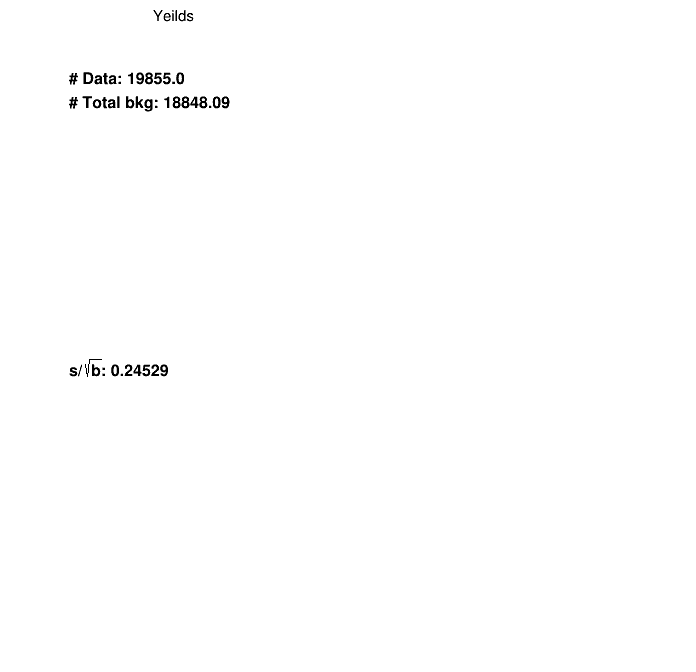

In [21]:
region = "SR"

with Pool() as p:
    p.starmap(wrapper_mp, list_variables)    

# for pie chart
hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str, is_dnn=False) 
hist.get_yeilds()
hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 171
DY1500To2000 : 163
DY2000To3000 : 117
DY500To700 : 156
DY700To800 : 132
DY800To1000 : 153
Zp-1700_CH-345 : 3157
Zp-1700_CH-595 : 2578
Zp-1700_CH-845 : 1919
Zp-2100_CH-345 : 2899
Zp-2100_CH-595 : 2309
Zp-2100_CH-845 : 1923
Zp-2500_CH-345 : 2675
Zp-2500_CH-595 : 2239
Zp-2500_CH-845 : 1784
Zp-2900_CH-1095 : 1330
Zp-2900_CH-1345 : 1143
Zp-2900_CH-345 : 2624
Zp-2900_CH-595 : 2130
Zp-2900_CH-845 : 1624
Zp-3300_CH-1095 : 1235
Zp-3300_CH-1345 : 1028
Zp-3300_CH-1595 : 934
Zp-3300_CH-345 : 2364
Zp-3300_CH-595 : 1957
Zp-3700_CH-1095 : 1159
Zp-3700_CH-1345 : 1004
Zp-3700_CH-1595 : 821
Zp-3700_CH-1845 : 748
Zp-3700_CH-345 : 2210
Zp-3700_CH-595 : 1804
Zp-3700_CH-845 : 1356
Zp-4100_CH-1095 : 1125
Zp-4100_CH-1345 : 890
Zp-4100_CH-1595 : 770
Zp-4100_CH-1845 : 692
Zp-4100_CH-345 : 1990
Zp-4100_CH-595 : 1713
Zp-4100_CH-845 : 1334

       0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([1.44125056e+00, 2.17106135e+01, 6.07424323e+01, 9.68767257e+01,
       9.57054425e+01, 2.36582173e+01, 5.01548519e+01, 4.09136053e+02,
       1.21702992e+03, 7.32746780e+02, 7.43511905e+01, 1.42109552e+01,
       8.23536303e+01, 1.19953872e+02, 5.14999941e+01, 3.04143898e+01,
       1.28045489e+01, 1.50366237e+00, 9.68941159e-01, 3.89423522e-03,
       3.71631837e-02, 4.76880872e-03, 4.42636516e-04, 4.33613106e-06,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([1.59437492e+00, 2.13400472e+01, 5.69767117e+01, 1.10573293e+02,
       1.34256679e+02, 6.21249089e+01, 6.58419671e+01, 4.89282751e+02,
       1.17266702e+03, 8.23406678e+02, 7.79965001e+01, 2.45309775e+01,
       1.28

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}{'puweightUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , -7.13840158, -5.58069718, -1.94288163, -6.57795898]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  3.00814481, -0.05478876,  0.88192695,  5.70912113]), 'l1prefiringUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , 18.32540932, 17.15543628, 15.48165577, 14.38015896]), 'l1prefiringDown':

       0., 0., 0.])}

{'puweightUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  9.04893522,  0.        ,  0.77779515, 32.59406405]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , 50.95677718, 31.14718277,  3.77478904, 43.26954436]), 'l1prefiringUp': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       335.8206267 , 294.30899412, 239.68166539, 206.7889718 ]), 'l1prefiringDown': array([  0.   

       3.60802403e-02, 1.40432846e-02, 1.11686239e-02])}
{'puweightUp': array([-1.45796486e+01, -6.08369884e+00, -1.23646779e+00,  1.28111784e+00,
        2.03196624e-01,  7.54075476e-02, -3.33756117e-01, -3.87823790e-02,
       -1.93080845e-01, -2.69539775e-01, -2.69687877e-01, -5.72245896e-02,
        9.53866193e-02, -8.66661342e-02, -1.27107152e-01,  3.64013764e-01,
        3.90645887e-04, -1.51034881e-02,  1.14509418e-02, -2.10812739e-03,
       -4.01221774e-03,  9.15679221e-03,  1.32927260e-02, -1.36543436e-02,
       -3.40973060e-03,  2.52653385e-03,  5.43516421e-03,  0.00000000e+00,
        1.48143994e-02, -2.18095597e-03]), 'puweightDown': array([ 7.80815917e+00,  3.41889508e+00, -1.81017238e+00, -5.06208165e-01,
       -1.63940595e-01,  4.20738379e-01,  1.79654391e-01, -3.79893248e-03,
        1.04698157e-02,  1.75812979e-01,  1.49031285e-01, -2.87859960e-02,
       -8.48556598e-02,  1.26239447e-01,  6.54964782e-02, -1.88452437e-01,
        1.65962333e-02, -1.17263879e-02,  6.

       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
{'puweightUp': array([6.09673497e+01, 1.16888436e+01, 0.00000000e+00, 1.64126292e+00,
       4.12888679e-02, 1.82707082e-01, 3.22757002e-02, 0.00000000e+00,
       1.09617041e-04, 3.09102037e-02, 2.22103240e-02, 0.00000000e+00,
       9.09860714e-03, 1.59363979e-02, 4.28978865e-03, 1.32506021e-01,
       2.75587565e-04, 0.00000000e+00, 1.74286886e-04, 1.55567780e-06,
       3.12544492e-04, 8.38468436e-05, 1.76696565e-04, 0.00000000e+00,
       1.01625387e-05, 6.38337329e-06, 2.95410099e-05, 0.00000000e+00,
       2.19466430e-04, 2.65680485e-06]), 'puweightDown': array([2.12566153e+02, 3.70113916e+01, 4.80557664e+00, 2.56246707e-01,
       2.68765187e-02, 0.00000000e+00, 1.11393146e-01, 1.51850481e-03,
       3.72802126e-02, 7.26516902e-02, 7.27315508e-02, 4.10328722e-03,
       7.20048299e-03, 7.51101881e-03, 1.61562280e-02, 3.55143210e-02,
       0.00000000e+00, 3.65623525e-04, 0.00000000e+00, 4.44420108e-06,
       1.609789

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_MET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET

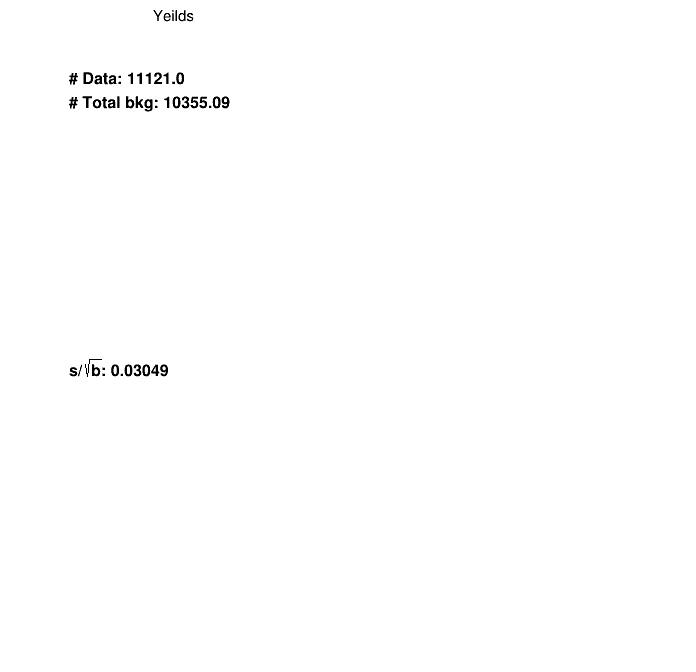

In [22]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d[key]=dic_df_met_d[key].query(query_str)     
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d    
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
        "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str, is_dnn=False) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [23]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [24]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d[key]=dic_df_met_d[key].query(query_str)     
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [20, 0, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
        "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
        "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str, is_dnn=False) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)  

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 117
DY1500To2000 : 107
DY2000To3000 : 87
DY500To700 : 127
DY700To800 : 109
DY800To1000 : 117
Zp-1700_CH-345 : 2894
Zp-1700_CH-595 : 2470
Zp-1700_CH-845 : 2025
Zp-2100_CH-345 : 2830
Zp-2100_CH-595 : 2395
Zp-2100_CH-845 : 2054
Zp-2500_CH-345 : 2525
Zp-2500_CH-595 : 2370
Zp-2500_CH-845 : 1948
Zp-2900_CH-1095 : 1571
Zp-2900_CH-1345 : 1383
Zp-2900_CH-345 : 2401
Zp-2900_CH-595 : 2204
Zp-2900_CH-845 : 1874
Zp-3300_CH-1095 : 1430
Zp-3300_CH-1345 : 1288
Zp-3300_CH-1595 : 1066
Zp-3300_CH-345 : 2201
Zp-3300_CH-595 : 2145
Zp-3700_CH-1095 : 1354
Zp-3700_CH-1345 : 1188
Zp-3700_CH-1595 : 998
Zp-3700_CH-1845 : 844
Zp-3700_CH-345 : 2015
Zp-3700_CH-595 : 2037
Zp-3700_CH-845 : 1752
Zp-4100_CH-1095 : 1380
Zp-4100_CH-1345 : 1135
Zp-4100_CH-1595 : 956
Zp-4100_CH-1845 : 867
Zp-4100_CH-345 : 1936
Zp-4100_CH-595 : 1876
Zp-4100_CH-845 : 161

         0.        ,   0.        ,   0.        , 137.07455603])}
{'puweightUp': array([-3.72862308,  0.39899646,  0.16791442, -2.32533276, -0.89756064,
        0.91767115, -1.42210199,  1.76078674, -0.24252393, -0.38479498,
        0.26489006,  0.07384302, -0.05103555, -0.36671861, -0.13238282,
       -0.09294117, -0.05731509, -0.16449859, -0.14972997, -0.01539344,
       -0.0781877 ,  0.02540258, -0.00944065, -0.05801596, -0.03192815,
       -0.03409243,  0.01520336, -0.01198299, -0.01552808,  0.00775163,
       -0.01026811]), 'puweightDown': array([ 0.59479291, -0.97773715, -0.80733198,  2.31640857,  1.11955456,
       -0.34777488,  1.288771  , -0.84857005,  0.13335846,  0.43047359,
       -0.07088385,  0.14655867, -0.12131279,  0.30142833,  0.0485945 ,
        0.10763896,  0.0694579 ,  0.02235171,  0.23165052, -0.0515292 ,
        0.05230299, -0.03428881, -0.00585221,  0.06594988,  0.01344135,
        0.00787027, -0.02112984,  0.01159483,  0.02265849,  0.01970513,
        0.03274924

{'puweightUp': array([ 1.71768747e-01,  5.62177826e-01,  1.23799010e+00,  1.96049276e+00,
        2.36610280e+00,  3.26914411e+00,  1.07533486e+00,  2.89553570e+00,
        7.21311593e-02, -4.41833823e+00, -6.13229298e+00, -7.66950686e+00,
       -7.98761156e+00, -2.40655944e+00, -1.47534204e+00,  7.25416170e-01,
        1.65533896e+00,  2.08487793e+00,  6.42632211e-01,  1.75346995e+00,
        5.25233946e-01,  6.88886714e-01,  1.52703573e+00, -1.02962568e-01,
       -1.97976033e-01, -9.99812146e-03,  2.06538726e-02, -1.77387219e-01,
        3.93456995e-01, -3.93932263e-02, -1.25200818e-01, -2.85177722e-03,
        4.33928523e-02, -5.64327219e-02,  1.45375906e-01,  1.04814509e-02,
       -5.79144167e-02, -5.64341410e-02, -5.21343493e-02,  4.93468496e-01]), 'puweightDown': array([-1.82664835e-01, -5.28946371e-01, -9.78071831e-01, -1.96429928e+00,
       -2.44981860e+00, -3.25166459e+00, -2.78765234e+00, -3.86316859e+00,
       -1.27556959e+00,  3.99737170e+00,  6.62980487e+00,  8.088101

       1.55406969e-02, 2.26894691e-03, 1.50085722e-02])}
{'puweightUp': array([2.95045025e-02, 3.16043908e-01, 1.53261948e+00, 3.84353185e+00,
       5.59844244e+00, 1.06873032e+01, 1.15634506e+00, 8.38412697e+00,
       5.20290414e-03, 1.59789805e+01, 4.39543126e+01, 6.54173915e+01,
       6.09756649e+01, 3.95173782e+00, 1.11081427e+00, 5.26228620e-01,
       2.74014706e+00, 4.34671597e+00, 4.12976158e-01, 3.07465686e+00,
       2.75870698e-01, 4.74564904e-01, 2.33183813e+00, 0.00000000e+00,
       1.43856057e-02, 3.87376860e-02, 4.26582454e-04, 5.33801798e-03,
       1.54808407e-01, 1.40633723e-03, 7.02051825e-03, 5.99094523e-05,
       1.88293963e-03, 0.00000000e+00, 2.23136227e-02, 1.08325392e-03,
       1.05556233e-02, 3.31747166e-03, 7.88789561e-03, 2.43511156e-01]), 'puweightDown': array([3.33664421e-02, 2.79784263e-01, 9.56624506e-01, 3.85847166e+00,
       6.00161119e+00, 1.05733226e+01, 7.77100557e+00, 1.49240716e+01,
       1.62707777e+00, 1.95217127e+01, 3.76050173e+01, 5.8

        0.16814392,  0.17503136,  0.11297471,  0.10913038,  0.71173448])}
{'puweightUp': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'puweightDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'l1prefiringUp': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'l1prefiringDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'effSFUp': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'effSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'topSFUp': array([0

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_MET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230226_17/Presel/em17/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Warning in <TCanvas::C

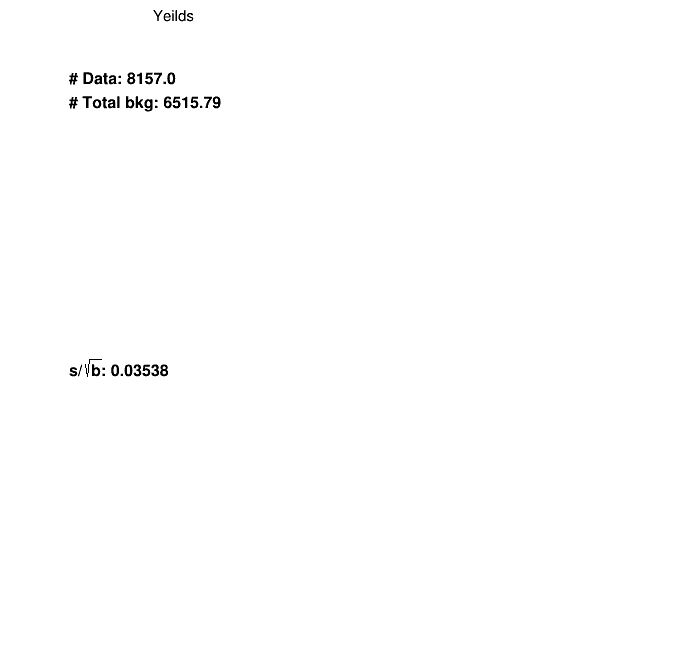

In [25]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d[key]=dic_df_met_d[key].query(query_str)     
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d    
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
        "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str, is_dnn=False) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [26]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [27]:
if DIVIDE_BY_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
        "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
        "njet_l_pre": [9, 1, 10, "N  l jet"],     
        "njet_c_pre": [9, 1, 10, "N  c jet"],     
        "njet_b_pre": [9, 1, 10, "N  b jet"],    
        "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
    query_str=base_line+" and njet_pre==1" #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "btag0"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Nj1/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Nj1/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Nj1/"+sys_key+"/pie_"+query_str)
    print(hist.nbin)    
    
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
    query_str=base_line+" and njet_pre==1 and nbjetflav_pre==1" #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
    
    print(dic_df_raw['TT'][['genweight_pre', 'weight', 'btagSF0_pre', 'btag0']])
    
    sys_list = ["weight", "btag0"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Nj1Nb1/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Nj1Nb1/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Nj1Nb1/"+sys_key+"/pie_"+query_str)
    print(hist.nbin)
    
    dic_df_raw={}
    query_str=base_line+" and njet_pre==1 and nbjetflav_pre==0"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)    
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
    
    sys_list = ["weight", "btag0"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Nj1Nb0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Nj1Nb0/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Nj1Nb0/"+sys_key+"/pie_"+query_str)
    print(hist.nbin)     

# Export variables

In [28]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file sigeff_em17.pdf has been created


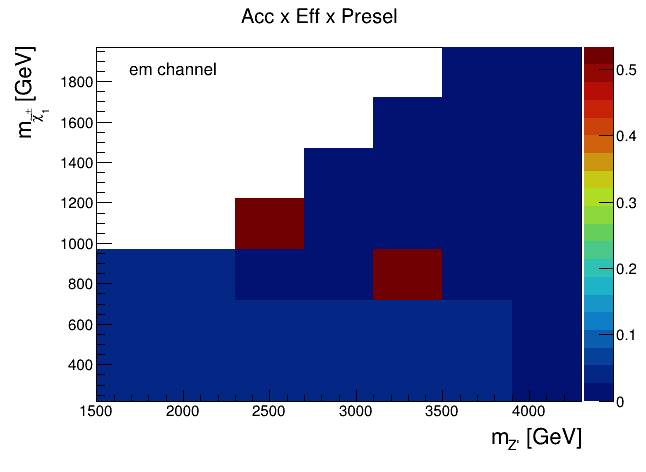

In [29]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")